# Laborator la obiectul: Rețele neurale și învățare profundă

# Lucrarea de laborator nr. 1: 
Crearea unei rețele neuronale artificiale (RNA) cu straturi Dense pentru operații de clasificare binară sau regresie.

## Scopul lucrării : 
Înțelegerea noțiunii de perceptron, a parametrilor necesari creării unei RNA. Antrenarea rețelei și validarea rezultatelor.

# A efectuat: Pleșu Cătălin
# A verificat: Mariana Rusu

## L4. Crearea unei rețele neuronale cu straturi Dense pentru operații simple.
### (de exemplu pentru clasificare binară). Antrenarea rețelei și validarea rezultatelor.

## Introducere

Scopul acestei lucrări este de a crea și optimiza o Rețea Neuronală Artificială (RNA) pentru clasificare binară. Se va folosi un set de date etichetat, iar modelul va fi construit folosind Keras/TensorFlow.

Vom parcurge pașii standard ai fluxului de lucru: încărcarea datelor, preprocesare, construire model, antrenare, evaluare și optimizare.


Aici au fost importate librăriile necesare pentru efectuarea lucrării.
Din motive necunoscute, prima execuție generează o eroare, iar a doua rulează ok.

In [2]:
# asta trebuie de executat 2 ori, prima data da o eroare
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split

In [5]:
# Adult Census Income - recensamantul venitului la adulti
# https://www.kaggle.com/datasets/uciml/adult-census-income

Utilizând librăria pandas a fost încărcat datasetul,
și au fost vizualizate primele 10 rânduri.

In [6]:
data = pd.read_csv("data/adult_census.csv")
data.head(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K


Nu am văzut rost în coloana 'fnlwgt', așa că am șters-o.

In [7]:
# sterge coloana cu date nefolositoare
data.drop(['fnlwgt'] , axis = 1 , inplace = True)

Aici s-a verificat dacă sunt celule cu valori nule, iar acestea nu au fost identificate.

O problemă potențială este că unele câmpuri au valoarea ''?'', ceea ce ar putea fi considerat null.

In [8]:
# Check if Data has any null values 
data.isnull().sum()

age               0
workclass         0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [10]:
# verificam tipul datelor din coloane
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   education       32561 non-null  object
 3   education.num   32561 non-null  int64 
 4   marital.status  32561 non-null  object
 5   occupation      32561 non-null  object
 6   relationship    32561 non-null  object
 7   race            32561 non-null  object
 8   sex             32561 non-null  object
 9   capital.gain    32561 non-null  int64 
 10  capital.loss    32561 non-null  int64 
 11  hours.per.week  32561 non-null  int64 
 12  native.country  32561 non-null  object
 13  income          32561 non-null  object
dtypes: int64(5), object(9)
memory usage: 3.5+ MB


In [11]:
# Label encode Object Datatypes 

data_types_dict = dict(data.dtypes)
# Keep track Mappings Column name to LabelEncoders
Label_encoder_collection = {}
for col_name , data_type in data_types_dict.items():
    if data_type == 'object':
        Le = LabelEncoder()
        data[col_name] = Le.fit_transform(data[col_name])
        Label_encoder_collection[col_name] = Le 

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  int64
 2   education       32561 non-null  int64
 3   education.num   32561 non-null  int64
 4   marital.status  32561 non-null  int64
 5   occupation      32561 non-null  int64
 6   relationship    32561 non-null  int64
 7   race            32561 non-null  int64
 8   sex             32561 non-null  int64
 9   capital.gain    32561 non-null  int64
 10  capital.loss    32561 non-null  int64
 11  hours.per.week  32561 non-null  int64
 12  native.country  32561 non-null  int64
 13  income          32561 non-null  int64
dtypes: int64(14)
memory usage: 3.5 MB


In [12]:
# din interes sportiv vom printa cum au fost encodate stringurile in integeruri
for col_name, label_encoder in Label_encoder_collection.items():
    print(f"Label Encoding mapping for column: {col_name}")
    # Get the mapping (original labels to encoded integers)
    mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
    print(mapping)
    print("-" * 30)

Label Encoding mapping for column: workclass
{'?': np.int64(0), 'Federal-gov': np.int64(1), 'Local-gov': np.int64(2), 'Never-worked': np.int64(3), 'Private': np.int64(4), 'Self-emp-inc': np.int64(5), 'Self-emp-not-inc': np.int64(6), 'State-gov': np.int64(7), 'Without-pay': np.int64(8)}
------------------------------
Label Encoding mapping for column: education
{'10th': np.int64(0), '11th': np.int64(1), '12th': np.int64(2), '1st-4th': np.int64(3), '5th-6th': np.int64(4), '7th-8th': np.int64(5), '9th': np.int64(6), 'Assoc-acdm': np.int64(7), 'Assoc-voc': np.int64(8), 'Bachelors': np.int64(9), 'Doctorate': np.int64(10), 'HS-grad': np.int64(11), 'Masters': np.int64(12), 'Preschool': np.int64(13), 'Prof-school': np.int64(14), 'Some-college': np.int64(15)}
------------------------------
Label Encoding mapping for column: marital.status
{'Divorced': np.int64(0), 'Married-AF-spouse': np.int64(1), 'Married-civ-spouse': np.int64(2), 'Married-spouse-absent': np.int64(3), 'Never-married': np.int64

In [13]:
data.head()

,age,workclass,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,0,11,9,6,0,1,4,0,0,4356,40,39,0
1,82,4,11,9,6,4,1,4,0,0,4356,18,39,0
2,66,0,15,10,6,0,4,2,0,0,4356,40,39,0
3,54,4,5,4,0,7,4,4,0,0,3900,40,39,0
4,41,4,15,10,5,10,3,4,0,0,3900,40,39,0


In [16]:
X = data.drop(columns="income").astype(np.float32)
Y = data["income"].astype(int)

In [18]:
X

,age,workclass,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,90.0,0.0,11.0,9.0,6.0,0.0,1.0,4.0,0.0,0.0,4356.0,40.0,39.0
1,82.0,4.0,11.0,9.0,6.0,4.0,1.0,4.0,0.0,0.0,4356.0,18.0,39.0
2,66.0,0.0,15.0,10.0,6.0,0.0,4.0,2.0,0.0,0.0,4356.0,40.0,39.0
3,54.0,4.0,5.0,4.0,0.0,7.0,4.0,4.0,0.0,0.0,3900.0,40.0,39.0
4,41.0,4.0,15.0,10.0,5.0,10.0,3.0,4.0,0.0,0.0,3900.0,40.0,39.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22.0,4.0,15.0,10.0,4.0,11.0,1.0,4.0,1.0,0.0,0.0,40.0,39.0
32557,27.0,4.0,7.0,12.0,2.0,13.0,5.0,4.0,0.0,0.0,0.0,38.0,39.0
32558,40.0,4.0,11.0,9.0,2.0,7.0,0.0,4.0,1.0,0.0,0.0,40.0,39.0
32559,58.0,4.0,11.0,9.0,6.0,1.0,4.0,4.0,0.0,0.0,0.0,40.0,39.0


In [17]:
Y

0        0
1        0
2        0
3        0
4        0
        ..
32556    0
32557    0
32558    1
32559    0
32560    0
Name: income, Length: 32561, dtype: int64

In [19]:
Xtrain , Xtest , Ytrain , Ytest = train_test_split(X, Y, test_size = 0.3, random_state = 888)

In [27]:
# normalizare, nu stiu ce face dar da rezultate mai bune
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

Aici a fost creată rețeaua RNA cu 3 straturi de 32, 32 și 1 neuron.

In [28]:
# numarul de neuroni de input
input_shape = Xtrain.shape[1]

# Start your model with Sequential Object  
model = tf.keras.models.Sequential()
# Next add in your Input object and Specify the Dimension you want to pass in 
model.add(tf.keras.Input(shape=(input_shape,)))
# Add in your Neurons of 1st layer
model.add(tf.keras.layers.Dense(32))
# 2nd layer 
model.add(tf.keras.layers.Dense(32))
# Final Sigmoid layer to predict (0/1)
model.add(tf.keras.layers.Dense(1 , activation='sigmoid'))

# print summary to undertstand your neural network flow
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Create your optimizer and compile your model
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(Optimizer, loss='binary_crossentropy', metrics=["accuracy"])

In [30]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest), epochs=20)

Epoch 1/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7885 - loss: 0.4478 - val_accuracy: 0.8188 - val_loss: 0.3964
Epoch 2/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8231 - loss: 0.3907 - val_accuracy: 0.8256 - val_loss: 0.3925
Epoch 3/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8254 - loss: 0.3808 - val_accuracy: 0.8248 - val_loss: 0.3914
Epoch 4/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8257 - loss: 0.3851 - val_accuracy: 0.8188 - val_loss: 0.3909
Epoch 5/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8235 - loss: 0.3873 - val_accuracy: 0.8168 - val_loss: 0.3932
Epoch 6/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8251 - loss: 0.3867 - val_accuracy: 0.8227 - val_loss: 0.3914
Epoch 7/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8309 - loss: 0.3779 - val_accuracy: 0.8196 - val_loss: 0.3931
Epoch 8/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8303 - loss: 0.3785 - val_accuracy: 0.

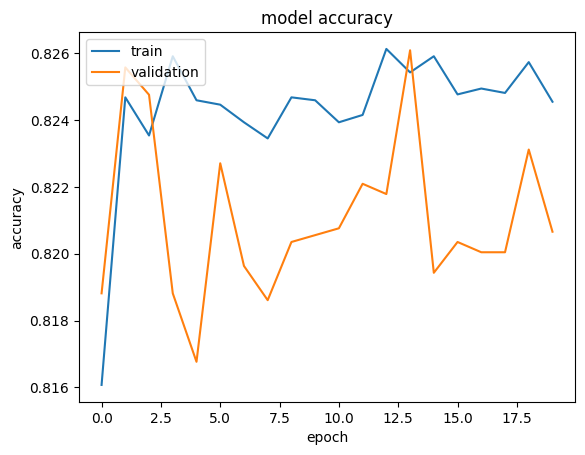

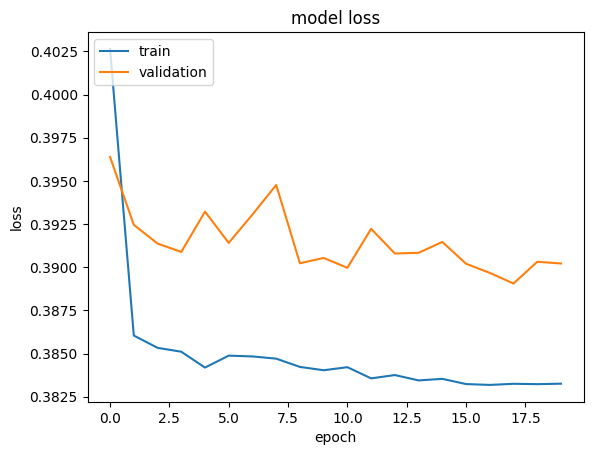

In [31]:
#  "Accuracy Plot"
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# We see a lot of fluctuations in Accuracy Graph which concludes model learning is unstable 

In [32]:
# collect predictions 
predictions = np.round(model.predict(Xtest))

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [33]:
# Check Accuracy
from sklearn.metrics import accuracy_score , confusion_matrix
accuracy_score(Ytest , predictions) # Accuracy Seems good

0.8206571808782884

In [34]:
confusion_matrix(Ytest , predictions)

array([[6954,  470],
       [1282, 1063]])

In [35]:
from sklearn.metrics import classification_report 

print(classification_report(Ytest , predictions))

              precision    recall  f1-score   support

           0       0.84      0.94      0.89      7424
           1       0.69      0.45      0.55      2345

    accuracy                           0.82      9769
   macro avg       0.77      0.69      0.72      9769
weighted avg       0.81      0.82      0.81      9769



In [36]:
# we will try to improve our model's performance 
# ----------- Add class weights when Data is Imbalanced -----------------------
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight = 'balanced',  classes = np.unique(Ytrain), y=Ytrain)

model_class_weights = {}
for e , weight in enumerate(class_weights):
    model_class_weights[e] = weight

In [37]:
model_class_weights

{0: np.float64(0.6588806660499538), 1: np.float64(2.0735080058224162)}

In [65]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20, class_weight=model_class_weights)

Epoch 1/20
219/219 [==============================] - 2s 4ms/step - loss: 0.5021 - accuracy: 0.7834 - val_loss: 0.4533 - val_accuracy: 0.7850
Epoch 2/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4887 - accuracy: 0.7680 - val_loss: 0.4715 - val_accuracy: 0.7860
Epoch 3/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4890 - accuracy: 0.7670 - val_loss: 0.4346 - val_accuracy: 0.7907
Epoch 4/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4856 - accuracy: 0.7690 - val_loss: 0.4519 - val_accuracy: 0.7827
Epoch 5/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4707 - accuracy: 0.7754 - val_loss: 0.4502 - val_accuracy: 0.7933
Epoch 6/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4742 - accuracy: 0.7763 - val_loss: 0.4318 - val_accuracy: 0.7913
Epoch 7/20
219/219 [==============================] - 1s 3ms/step - loss: 0.4716 - accuracy: 0.7751 - val_loss: 0.4440 - val_accuracy: 0.7947
Epoch 

In [66]:
# collect predictions 
predictions = np.round(model.predict(Xtest))

94/94 [==============================] - 0s 1ms/step


In [67]:
confusion_matrix(Ytest , predictions)

array([[1910,  468],
       [ 159,  463]], dtype=int64)

In [46]:
# Better results for recognizing second-class items, but much worse for first-class items.

In [68]:
# Increase Units in Dense layers and Also Increase Number of Layers 
# Add BatchNormalization to Layers 
# Add Dropout after Layers 

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(10,)))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dense(128 , activation='relu'))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dense(64 , activation='relu'))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dense(32 , activation='relu'))
model.add(tf.keras.layers.Dense(1 , activation='sigmoid'))

# print summary to undertstand your neural network flow
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 batch_normalization_6 (Bat  (None, 10)                40        
 chNormalization)                                                
                                                                 
 dense_14 (Dense)            (None, 128)               1408      
                                                                 
 dropout_4 (Dropout)         (None, 128)               0         
                                                                 
 batch_normalization_7 (Bat  (None, 128)               512       
 chNormalization)                                                
                                                                 
 dense_15 (Dense)            (None, 64)                8256      
                                                                 
 dropout_5 (Dropout)         (None, 64)               

In [69]:
# Create your optimizer and compile your model
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(Optimizer, loss='binary_crossentropy', metrics=["accuracy"])

In [38]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20)

Epoch 1/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8231 - loss: 0.3874 - val_accuracy: 0.8213 - val_loss: 0.3896
Epoch 2/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8243 - loss: 0.3812 - val_accuracy: 0.8197 - val_loss: 0.3899
Epoch 3/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8261 - loss: 0.3798 - val_accuracy: 0.8212 - val_loss: 0.3900
Epoch 4/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8301 - loss: 0.3724 - val_accuracy: 0.8210 - val_loss: 0.3905
Epoch 5/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8256 - loss: 0.3812 - val_accuracy: 0.8220 - val_loss: 0.3902
Epoch 6/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8237 - loss: 0.3934 - val_accuracy: 0.8215 - val_loss: 0.3913
Epoch 7/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8204 - loss: 0.3889 - val_accuracy: 0.8214 - val_loss: 0.3903
Epoch 8/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8228 - loss: 0.3860 - val_accuracy: 0.

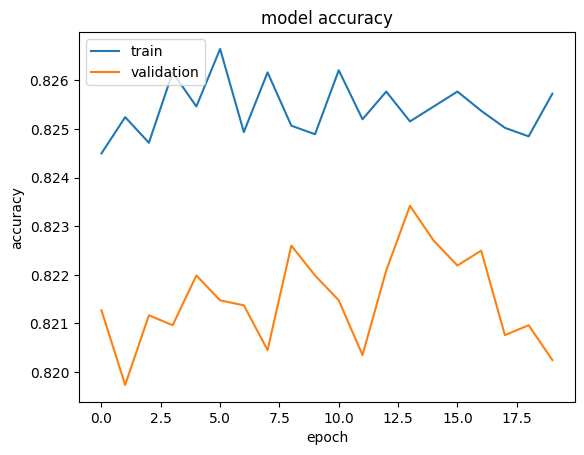

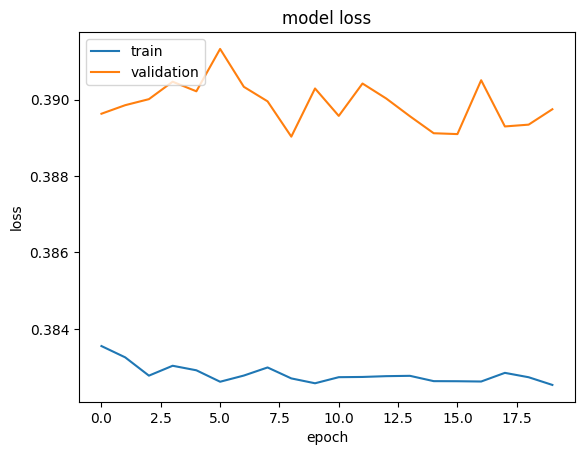

In [44]:
#  "Accuracy Plot"
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# We see graphs converging better compared to previous implementation

In [45]:
# collect predictions 
predictions = np.round(model.predict(Xtest))

306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [46]:
# Check Accuracy
accuracy_score(Ytest , predictions) # Accuracy is good

0.820247722387143

In [47]:
# We don't see the problem of predicting everything as class 0
confusion_matrix(Ytest , predictions)

array([[6951,  473],
       [1283, 1062]])

In [48]:
print(classification_report(Ytest, predictions))

              precision    recall  f1-score   support

           0       0.84      0.94      0.89      7424
           1       0.69      0.45      0.55      2345

    accuracy                           0.82      9769
   macro avg       0.77      0.69      0.72      9769
weighted avg       0.81      0.82      0.81      9769



## Choose either dataset to test binary classification. Create a 4-layer Dense network, 
## test with minimum neurons (64, 32, 16, 1), then Increase Units in Dense layers and 
## also Increase Number of Layers add BatchNormalization to Layers add Dropout after Layers.

In [49]:
Xtrain , Xtest , Ytrain , Ytest = train_test_split(X, Y, test_size = 0.3, random_state = 888)

In [50]:
# normalizare, nu stiu ce face dar da rezultate mai bune
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

In [68]:
# numarul de neuroni de input
input_shape = Xtrain.shape[1]

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(input_shape,)))

model.add(tf.keras.layers.Dense(128 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(64 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(32 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(1 , activation='sigmoid'))

# print summary to undertstand your neural network flow
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,057 (51.00 KB)

 Trainable params: 12,609 (49.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [69]:
# Create your optimizer and compile your model
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(Optimizer, loss='binary_crossentropy', metrics=["accuracy"])

In [70]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest), epochs=20)

Epoch 1/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.7249 - loss: 0.5547 - val_accuracy: 0.8407 - val_loss: 0.3462
Epoch 2/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8182 - loss: 0.3855 - val_accuracy: 0.8394 - val_loss: 0.3396
Epoch 3/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8313 - loss: 0.3609 - val_accuracy: 0.8450 - val_loss: 0.3336
Epoch 4/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8368 - loss: 0.3521 - val_accuracy: 0.8455 - val_loss: 0.3320
Epoch 5/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8375 - loss: 0.3462 - val_accuracy: 0.8439 - val_loss: 0.3310
Epoch 6/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8427 - loss: 0.3400 - val_accuracy: 0.8440 - val_loss: 0.3322
Epoch 7/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8366 - loss: 0.3425 - val_accuracy: 0.8449 - val_loss: 0.3291
Epoch 8/20
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8367 - loss: 0.3424 - val_accuracy: 0.

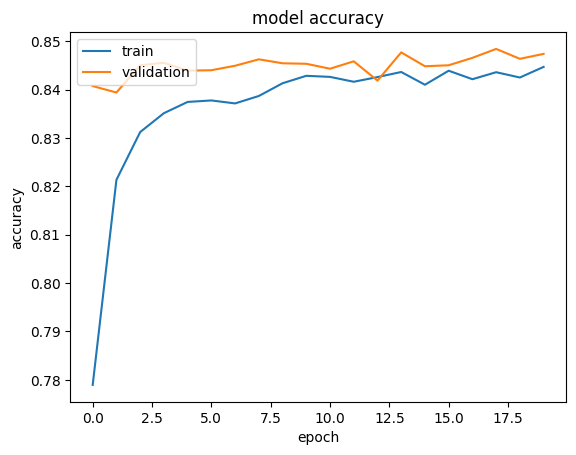

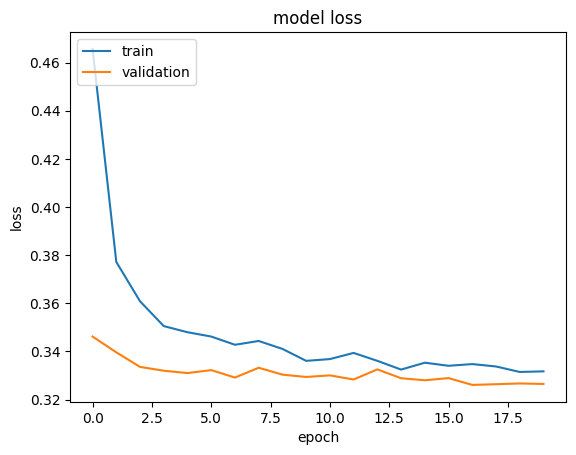

In [71]:
#  "Accuracy Plot"
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# We see a lot of fluctuations in Accuracy Graph which concludes model learning is unstable 

In [72]:
# collect predictions 
predictions = np.round(model.predict(Xtest))
# Check Accuracy
from sklearn.metrics import accuracy_score , confusion_matrix
accuracy_score(Ytest , predictions) # Accuracy Seems good

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


0.8473743474255298

pare ca daca idenfifica clasa 1 (venit <50k) probabilitatea ca este corect este de 92%
daca identifica clasa 2 (venit >50%) probabilitatea este 59%

In [73]:
# We don't see the problem of predicting everything as class 0
confusion_matrix(Ytest , predictions)

array([[6892,  532],
       [ 959, 1386]])

In [74]:
from sklearn.metrics import classification_report
print(classification_report(Ytest , predictions))

              precision    recall  f1-score   support

           0       0.88      0.93      0.90      7424
           1       0.72      0.59      0.65      2345

    accuracy                           0.85      9769
   macro avg       0.80      0.76      0.78      9769
weighted avg       0.84      0.85      0.84      9769



In [65]:
# we will try to improve our model's performance 
# ----------- Add class weights when Data is Imbalanced -----------------------
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight = 'balanced',  classes = np.unique(Ytrain), y=Ytrain)

model_class_weights = {}
for e , weight in enumerate(class_weights):
    model_class_weights[e] = weight

In [66]:
model_class_weights

{0: np.float64(0.6588806660499538), 1: np.float64(2.0735080058224162)}

In [67]:
print(classification_report(Ytest, predictions))

              precision    recall  f1-score   support

           0       0.87      0.94      0.90      7424
           1       0.74      0.57      0.64      2345

    accuracy                           0.85      9769
   macro avg       0.81      0.75      0.77      9769
weighted avg       0.84      0.85      0.84      9769



## Concluzii

Au fost dezvoltate două modele RNA, unul cu 3 nivele și altul cu 4 nivele. Modelul cu 4 nivele a demonstrat o performanță mai bună, având o acuratețe mai mare în clasificarea binară. În ceea ce privește performanța pe clase, modelul a obținut o probabilitate de corectitudine de 92% în identificarea clasei 1 (venit <50k), în timp ce pentru clasa 2 (venit >50k), probabilitatea de corectitudine a fost de 59%. Aceasta sugerează că există oportunități semnificative de îmbunătățire a performanței în identificarea clasei 2.

Prin aplicarea tehnicilor de optimizare, capacitatea de generalizare a modelului a fost îmbunătățită, însă ajustări suplimentare sunt necesare pentru a reduce erorile, mai ales în ceea ce privește identificarea clasei 2. În viitor, implementarea de tehnici precum regularizarea L2 și augmentarea datelor ar putea contribui semnificativ la îmbunătățirea performanței globale ale modelului, în special în ceea ce privește clasificarea clasei 2.